<a href="https://colab.research.google.com/github/Amazingsai/Identifying-LLMs-from-Their-Responses/blob/main/Midterm_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
!pip install datascience --upgrade

In [43]:
import graphviz


print("Matplotlib is running")
from datascience import *
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, Conv1D, GlobalMaxPooling1D, Dense
from tensorflow.keras.layers import SimpleRNN
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import classification_report
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn import tree
from sklearn.tree import DecisionTreeClassifier
from sklearn import metrics
from sklearn.metrics import f1_score
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import confusion_matrix
from sklearn.base import ClassifierMixin
%matplotlib inline
import matplotlib.pyplot as plt

import pandas as pd
import numpy as np

import os
os.environ["PATH"] += os.pathsep + 'C:/Program Files (x86)/Graphviz2.38/bin/'

Matplotlib is running


In [4]:
!pip install -U datasets huggingface_hub

In [5]:
from huggingface_hub import login
login()

In [6]:
from datasets import load_dataset

dataset = load_dataset("lmsys/chatbot_arena_conversations")

README.md:   0%|          | 0.00/7.00k [00:00<?, ?B/s]

data/train-00000-of-00001-cced8514c7ed78(…): reconstructing file:   0%|          |  0.00B / 41.6MB            

data/train-00000-of-00001-cced8514c7ed78(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/33000 [00:00<?, ? examples/s]

In [7]:
df = dataset["train"].to_pandas()

df.to_csv(
    "/content/drive/MyDrive/CMPSC448Fall2026/chatbot_arena_conversations.csv",
    index=False
)

In [8]:
dataset

DatasetDict({
    train: Dataset({
        features: ['question_id', 'model_a', 'model_b', 'winner', 'judge', 'conversation_a', 'conversation_b', 'turn', 'anony', 'language', 'tstamp', 'openai_moderation', 'toxic_chat_tag'],
        num_rows: 33000
    })
})

In [9]:
df = dataset["train"].to_pandas()

print(df.shape)
print(df.columns)

(33000, 13)
Index(['question_id', 'model_a', 'model_b', 'winner', 'judge',
       'conversation_a', 'conversation_b', 'turn', 'anony', 'language',
       'tstamp', 'openai_moderation', 'toxic_chat_tag'],
      dtype='object')


In [10]:
clean_data = []

for _, row in df.iterrows():

    # Model A
    conversation_a = row["conversation_a"]

    # Find the first user message
    user_message_a = None
    for message in conversation_a:
        if message["role"] == "user":
            user_message_a = message["content"]
            break

    # Find the first assistant response
    assistant_message_a = None
    for message in conversation_a:
        if message["role"] == "assistant":
            assistant_message_a = message["content"]
            break

    if user_message_a is not None and assistant_message_a is not None:
        clean_data.append({
            "LLM_name": row["model_a"],
            "LLM_Input": user_message_a,
            "LLM_output": assistant_message_a
        })


    # Model B
    conversation_b = row["conversation_b"]

    # Find the first user message
    user_message_b = None
    for message in conversation_b:
        if message["role"] == "user":
            user_message_b = message["content"]
            break

    # Find the first assistant response
    assistant_message_b = None
    for message in conversation_b:
        if message["role"] == "assistant":
            assistant_message_b = message["content"]
            break

    if user_message_b is not None and assistant_message_b is not None:
        clean_data.append({
            "LLM_name": row["model_b"],
            "LLM_Input": user_message_b,
            "LLM_output": assistant_message_b
        })


clean_df = pd.DataFrame(clean_data)

In [ ]:
file_path = "/content/drive/MyDrive/CMPSC448Fall2026/LMSYS_clean.csv"
clean_df.to_csv(file_path, index=False)

print("Saved to:")
print(file_path)

Saved to:
/content/drive/MyDrive/CMPSC448Fall2026/LMSYS_clean.csv


In [11]:
file_path = "/content/drive/MyDrive/CMPSC448Fall2026/LMSYS_clean.csv"
clean_df_Table = Table.read_table(file_path)
clean_df_Table.show(5)
print(clean_df["LLM_name"].value_counts())

LLM_name,LLM_Input,LLM_output
chatglm-6b,What is the difference between OpenCL and CUDA?,OpenCL and CUDA are two different programming models tha ...
koala-13b,What is the difference between OpenCL and CUDA?,OpenCL and CUDA are both programming languages for paral ...
oasst-pythia-12b,Why did my parent not invite me to their wedding?,It is possible that your parent did not invite you to th ...
alpaca-13b,Why did my parent not invite me to their wedding?,It is likely that they wanted to keep the guest list sma ...
koala-13b,"Fuji vs. Nikon, which is better?",Both Fuji and Nikon are popular camera brands that offer ...


LLM_name
vicuna-13b                 5931
koala-13b                  5573
oasst-pythia-12b           4890
gpt-3.5-turbo              4654
alpaca-13b                 4453
gpt-4                      4217
claude-v1                  3927
RWKV-4-Raven-14B           3682
chatglm-6b                 3322
fastchat-t5-3b             3210
palm-2                     2955
vicuna-7b                  2869
mpt-7b-chat                2854
stablelm-tuned-alpha-7b    2795
dolly-v2-12b               2786
claude-instant-v1          2626
llama-13b                  2009
wizardlm-13b               1116
gpt4all-13b-snoozy         1097
guanaco-33b                1034
Name: count, dtype: int64


In [13]:
#filtering the table to select these specific models
selected_models = ["gpt-4","claude-v1","vicuna-13b","chatglm-6b","koala-13b"]
project_df_Table = clean_df_Table.where("LLM_name",are.contained_in(selected_models))

project_df_Table.show(5)

LLM_name,LLM_Input,LLM_output
chatglm-6b,What is the difference between OpenCL and CUDA?,OpenCL and CUDA are two different programming models tha ...
koala-13b,What is the difference between OpenCL and CUDA?,OpenCL and CUDA are both programming languages for paral ...
koala-13b,"Fuji vs. Nikon, which is better?",Both Fuji and Nikon are popular camera brands that offer ...
vicuna-13b,How to build an arena for chatbots?,Building an arena for chatbots can be done by following ...
vicuna-13b,When is it today?,"I'm sorry, I cannot determine the current date for you a ..."


In [14]:
# Seeing how many responses each LLM has
project_df_Table.group("LLM_name")

LLM_name,count
chatglm-6b,3322
claude-v1,3927
gpt-4,4217
koala-13b,5573
vicuna-13b,5931


In [15]:
chatglm = project_df_Table.where("LLM_name", are.equal_to("chatglm-6b")).sample(3000)

claude = project_df_Table.where("LLM_name", are.equal_to("claude-v1")).sample(3000)

gpt = project_df_Table.where("LLM_name", are.equal_to("gpt-4")).sample(3000)

koala = project_df_Table.where("LLM_name", are.equal_to("koala-13b")).sample(3000)

vicuna = project_df_Table.where("LLM_name", are.equal_to("vicuna-13b")).sample(3000)

In [16]:
#Making a new combined table
balanced_df_Table = chatglm
balanced_df_Table = balanced_df_Table.append(claude)
balanced_df_Table = balanced_df_Table.append(gpt)
balanced_df_Table = balanced_df_Table.append(koala)
balanced_df_Table = balanced_df_Table.append(vicuna)
balanced_df_Table.group("LLM_name")

LLM_name,count
chatglm-6b,3000
claude-v1,3000
gpt-4,3000
koala-13b,3000
vicuna-13b,3000


In [17]:
balanced_df_Table.show(5)
balanced_df_Table.num_rows

LLM_name,LLM_Input,LLM_output
chatglm-6b,"What is FastAPI ? If so, can you give some examples of it ?",FastAPI is an open-source framework for building RESTful ...
chatglm-6b,WHAT investments would be optimal for a tfsa,tfsa? Please provide more context or clarify your question.
chatglm-6b,Hi,Hello! How can I assist you today?
chatglm-6b,Please write a bash script that can pass arguments to a ...,Certainly! Here is a bash script that will check if the ...
chatglm-6b,"Riddle: David’s parents have three sons: Snap, Crackle, ...",The name of the third son is not specified in the given ...


15000

In [18]:
#Making a column tracking response lengths by applying len function to the output
response_lengths = balanced_df_Table.apply(len, "LLM_output")
balanced_df_Table = balanced_df_Table.with_column("Response_Length", response_lengths)
balanced_df_Table.show(5)

LLM_name,LLM_Input,LLM_output,Response_Length
chatglm-6b,"What is FastAPI ? If so, can you give some examples of it ?",FastAPI is an open-source framework for building RESTful ...,1101
chatglm-6b,WHAT investments would be optimal for a tfsa,tfsa? Please provide more context or clarify your question.,59
chatglm-6b,Hi,Hello! How can I assist you today?,34
chatglm-6b,Please write a bash script that can pass arguments to a ...,Certainly! Here is a bash script that will check if the ...,823
chatglm-6b,"Riddle: David’s parents have three sons: Snap, Crackle, ...",The name of the third son is not specified in the given ...,760


In [19]:
length_table = balanced_df_Table.select("LLM_name","Response_Length")

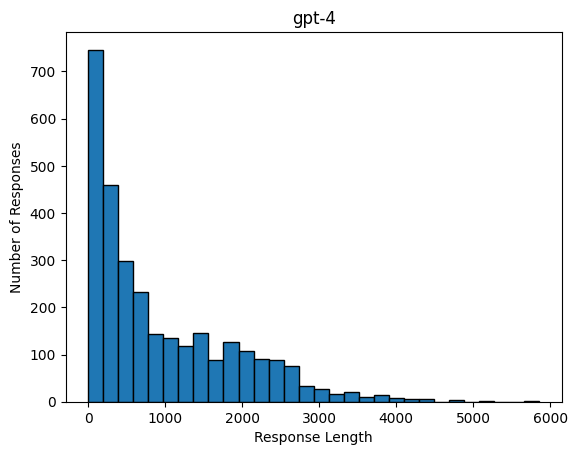

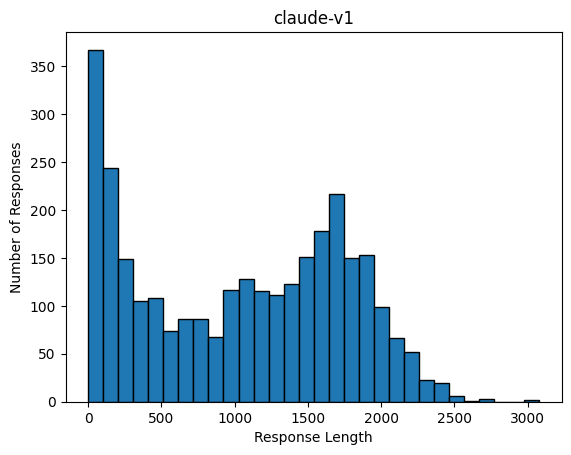

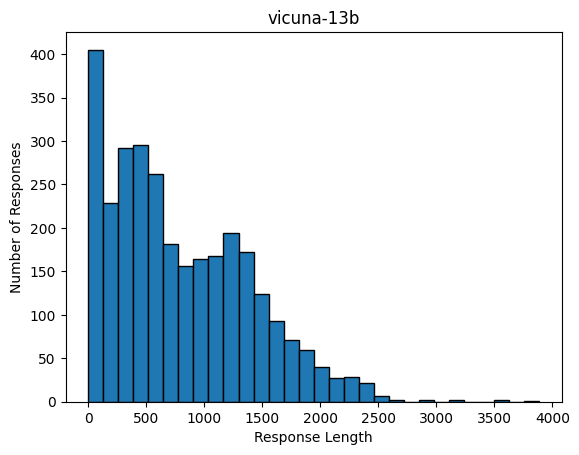

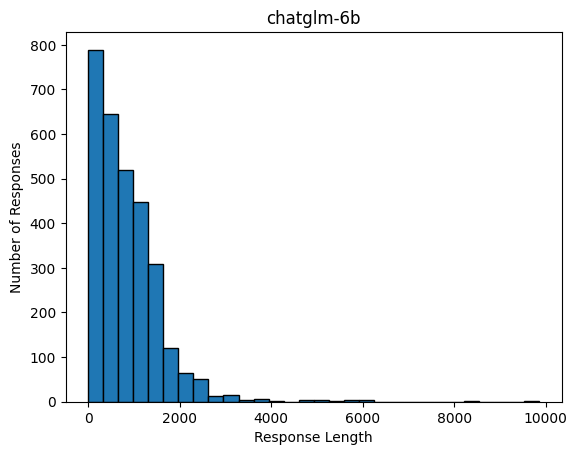

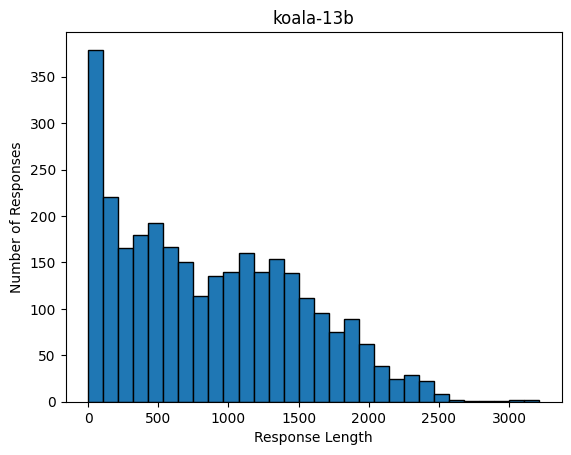

In [45]:
import matplotlib.pyplot as plt
for model in selected_models:
    model_data = length_table.where("LLM_name",are.equal_to(model))

    plt.hist(model_data.column("Response_Length"), bins=30)
    plt.title(model)
    plt.xlabel("Response Length")
    plt.ylabel("Number of Responses")
    plt.show()

In [30]:
word_counts = balanced_df_Table.apply(lambda text: len(text.split()),"LLM_output")

balanced_df_Table = balanced_df_Table.with_column("Word_Count",word_counts)


In [31]:
word_table = balanced_df_Table.select("LLM_name","Word_Count")

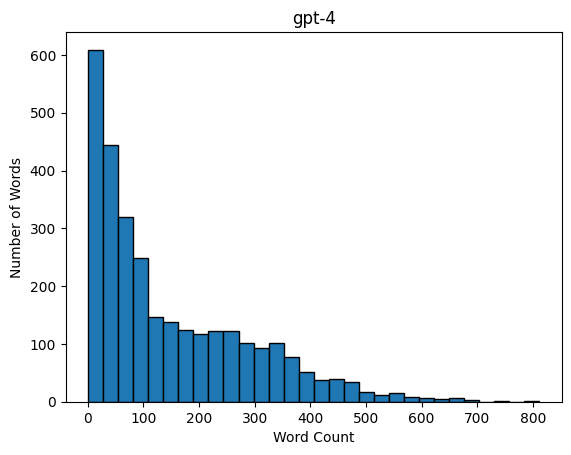

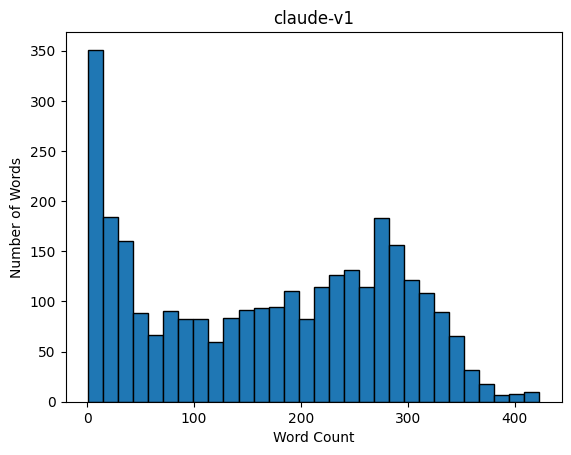

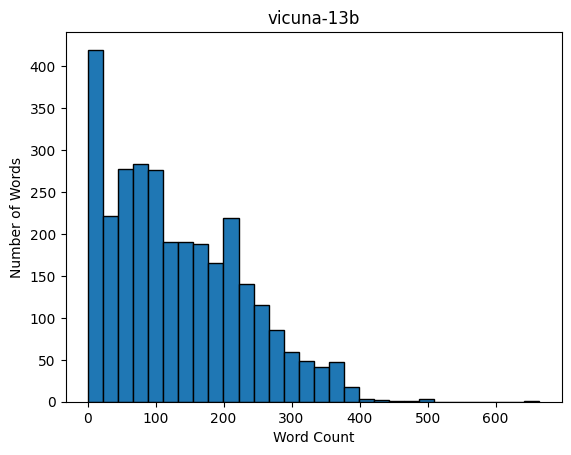

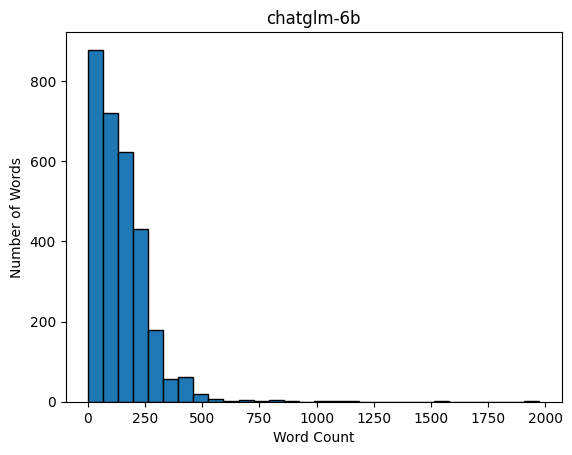

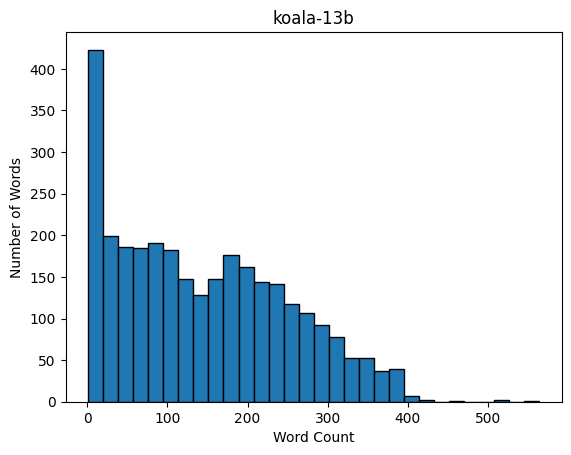

In [46]:
for model in selected_models:
    model_data = word_table.where("LLM_name",are.equal_to(model))

    plt.hist(model_data.column("Word_Count"), bins=30)
    plt.title(model)
    plt.xlabel("Word Count")
    plt.ylabel("Number of Words")
    plt.show()

In [47]:
#Next I count the sentances and make a new sentance column
import re

def count_sentences(text):
    return len(re.findall(r'[.!?]+', text))

sentence_counts = balanced_df_Table.apply(count_sentences, "LLM_output")
balanced_df_Table = balanced_df_Table.with_column("Sentence_Count", sentence_counts)

In [48]:
balanced_df_Table.show(5)

LLM_name,LLM_Input,LLM_output,Response_Length,Word_Count,Sentence_Count
chatglm-6b,"What is FastAPI ? If so, can you give some examples of it ?",FastAPI is an open-source framework for building RESTful ...,1101,176,14
chatglm-6b,WHAT investments would be optimal for a tfsa,tfsa? Please provide more context or clarify your question.,59,9,2
chatglm-6b,Hi,Hello! How can I assist you today?,34,7,2
chatglm-6b,Please write a bash script that can pass arguments to a ...,Certainly! Here is a bash script that will check if the ...,823,136,7
chatglm-6b,"Riddle: David’s parents have three sons: Snap, Crackle, ...",The name of the third son is not specified in the given ...,760,141,8


In [49]:


balanced_df_Table.group("LLM_name", np.mean)

LLM_name,LLM_Input mean,LLM_output mean,Response_Length mean,Word_Count mean,Sentence_Count mean
chatglm-6b,,,842.608,143.533,8.758
claude-v1,,,1041.42,170.108,12.8283
gpt-4,,,947.979,148.318,10.5093
koala-13b,,,878.43,144.435,8.96533
vicuna-13b,,,799.917,133.254,8.09533


In [ ]:
# because the  neural network can't directly use text labels, I converted them into numbers.

def get_class(llm):
    if llm == "chatglm-6b":
        return 0
    elif llm == "claude-v1":
        return 1
    elif llm == "gpt-4":
        return 2
    elif llm == "koala-13b":
        return 3
    elif llm == "vicuna-13b":
        return 4

class_labels = balanced_df_Table.apply(get_class, "LLM_name")

balanced_df_Table = balanced_df_Table.with_column("class", class_labels)


In [ ]:
balanced_df_Table.show(5)

LLM_name,LLM_Input,LLM_output,Response_Length,Word_Count,Sentence_Count,class
chatglm-6b,what is the best icd10 code for hypertension?,"The IICD-10 (International Classification of Diseases, 1 ...",101,13,2,0
chatglm-6b,Assume you are a writing professor who specializes in th ...,"The hook at the beginning of your essay can be: ""In Ind ...",330,55,2,0
chatglm-6b,How are you today?,"I'm just a computer program, so I don't have feelings. I ...",182,35,3,0
chatglm-6b,You are wandering through a desert and see a turtle lyin ...,"As an AI language model, I do not have personal feelings ...",1199,219,12,0
chatglm-6b,How to make a bunny happy,"There are many ways to make a bunny happy, depending on ...",538,93,3,0


In [ ]:
#TF-IDF
texts = balanced_df_Table.column("LLM_output")
labels = balanced_df_Table.column("class")

In [ ]:
# 12,000 training responses, 3,000 testing responses, and 69,601 TF-IDF features for each response
X_train, X_test, Y_train, Y_test = train_test_split(X,labels, test_size=0.2)
print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (12000, 69601)
Testing data: (3000, 69601)


In [ ]:
#CNN/RNN models work better with tokenized text sequences rather than a 69,601-column TF-IDF matrix. So I get new data
X_text_train, X_text_test, Y_train, Y_test = train_test_split(texts,labels, test_size=0.2)
print("Training responses:", len(X_text_train))
print("Testing responses:", len(X_text_test))

Training responses: 12000
Testing responses: 3000


In [ ]:
#keeping the 20,000 most common words in the dataset.
#not to self(<OOV> means out of vocabulary. If the model encounters a word it didn't keep, it gets represented by a special number instead of causing an error.)
tokenizer = Tokenizer(num_words=20000, oov_token="<OOV>")

In [ ]:
#Training the tokenizer using ONLY the training responses
tokenizer.fit_on_texts(X_text_train)

In [ ]:
# Converting the text to sequences with each number representing a word/token in the vocabulary.
X_train_sequences = tokenizer.texts_to_sequences(X_text_train)
X_test_sequences = tokenizer.texts_to_sequences(X_text_test)
print(X_text_train[0])
print(X_train_sequences[0])

Sure, I'd love to play hangman with you! What word would you like to choose?
[175, 2086, 209, 5, 318, 1, 16, 11, 116, 399, 61, 11, 54, 5, 445]


In [ ]:
#the neural network needs the inputs to have the same size so they'll all be the same length using padding.
# Finding a reasonable sequence length
lengths = [len(x) for x in X_train_sequences]

print("Average length:", np.mean(lengths))
print("Maximum length:", np.max(lengths))

Average length: 0
Average length: 149.852166667
Maximum length: 1989


In [ ]:
#Because the average was 149, using a max length of 200
#Pad the training and testing sequences
max_length = 200

X_train_padded = pad_sequences(
    X_train_sequences,
    maxlen=max_length,
    padding="post",
    truncating="post"
)

X_test_padded = pad_sequences(
    X_test_sequences,
    maxlen=max_length,
    padding="post",
    truncating="post"
)

In [ ]:
print("Training shape:", X_train_padded.shape)
print("Testing shape:", X_test_padded.shape)

Training shape: (12000, 200)
Testing shape: (3000, 200)


In [ ]:
#the output only CNN
vocab_size = min(20000, len(tokenizer.word_index) + 1)

cnn_model = Sequential([
    Embedding(input_dim=vocab_size, output_dim=128),
    Conv1D(128, 5, activation="relu"),
    GlobalMaxPooling1D(),
    Dense(64, activation="relu"),
    Dense(5, activation="softmax")
])

cnn_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

cnn_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d (Conv1D)                 │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_max_pooling1d            │ ?                      │             0 │
│ (GlobalMaxPooling1D)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [ ]:
#Training the output CNN
history_cnn = cnn_model.fit(
    X_train_padded,
    np.array(Y_train),
    validation_split=0.2,
    epochs=5,
    batch_size=32
)

Epoch 1/5
300/300 ━━━━━━━━━━━━━━━━━━━━ 40s 126ms/step - accuracy: 0.3828 - loss: 1.3894 - val_accuracy: 0.5258 - val_loss: 1.1363
Epoch 2/5
300/300 ━━━━━━━━━━━━━━━━━━━━ 41s 125ms/step - accuracy: 0.7106 - loss: 0.7887 - val_accuracy: 0.6354 - val_loss: 0.9248
Epoch 3/5
300/300 ━━━━━━━━━━━━━━━━━━━━ 39s 131ms/step - accuracy: 0.9360 - loss: 0.2353 - val_accuracy: 0.6550 - val_loss: 0.9589
Epoch 4/5
300/300 ━━━━━━━━━━━━━━━━━━━━ 37s 122ms/step - accuracy: 0.9752 - loss: 0.0798 - val_accuracy: 0.6542 - val_loss: 1.0322
Epoch 5/5
300/300 ━━━━━━━━━━━━━━━━━━━━ 39s 129ms/step - accuracy: 0.9810 - loss: 0.0541 - val_accuracy: 0.6521 - val_loss: 1.0819


In [ ]:
#Testing the output CNN
cnn_loss, cnn_accuracy = cnn_model.evaluate(
    X_test_padded,
    np.array(Y_test)
)

print("CNN Test Accuracy:", cnn_accuracy)

94/94 ━━━━━━━━━━━━━━━━━━━━ 2s 24ms/step - accuracy: 0.6400 - loss: 1.0938
CNN Test Accuracy: 0.6399999856948853


In [ ]:
#Building the output RNN
rnn_model = Sequential([
    Embedding(input_dim=vocab_size, output_dim=128),
    SimpleRNN(64),
    Dense(64, activation="relu"),
    Dense(5, activation="softmax")
])

rnn_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

rnn_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn (SimpleRNN)          │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [ ]:
#Training the output RNN
history_rnn = rnn_model.fit(
    X_train_padded,
    np.array(Y_train),
    validation_split=0.2,
    epochs=5,
    batch_size=32
)

Epoch 1/5
300/300 ━━━━━━━━━━━━━━━━━━━━ 29s 89ms/step - accuracy: 0.2491 - loss: 1.5819 - val_accuracy: 0.3025 - val_loss: 1.5219
Epoch 2/5
300/300 ━━━━━━━━━━━━━━━━━━━━ 26s 88ms/step - accuracy: 0.4271 - loss: 1.2818 - val_accuracy: 0.3233 - val_loss: 1.5027
Epoch 3/5
300/300 ━━━━━━━━━━━━━━━━━━━━ 25s 82ms/step - accuracy: 0.5056 - loss: 1.0561 - val_accuracy: 0.3192 - val_loss: 1.5516
Epoch 4/5
300/300 ━━━━━━━━━━━━━━━━━━━━ 41s 82ms/step - accuracy: 0.5205 - loss: 1.0283 - val_accuracy: 0.3379 - val_loss: 1.5987
Epoch 5/5
300/300 ━━━━━━━━━━━━━━━━━━━━ 41s 83ms/step - accuracy: 0.5334 - loss: 1.0090 - val_accuracy: 0.3300 - val_loss: 1.6805


In [ ]:
#Testing the output RNN
rnn_loss, rnn_accuracy = rnn_model.evaluate(
    X_test_padded,
    np.array(Y_test)
)

print("RNN Test Accuracy:", rnn_accuracy)

94/94 ━━━━━━━━━━━━━━━━━━━━ 3s 27ms/step - accuracy: 0.3327 - loss: 1.7328
RNN Test Accuracy: 0.33266666531562805


In [ ]:
#RQ2: Input only
#this time I will use the user's prompt (LLM_Input) instead of the generated response (LLM_output).

texts_input = balanced_df_Table.column("LLM_Input")
labels = balanced_df_Table.column("class")

X_input_train, X_input_test, Y_input_train, Y_input_test = train_test_split(
    texts_input,
    labels,
    test_size=0.2,
    random_state=42,
    stratify=labels
)

print("Training prompts:", len(X_input_train))
print("Testing prompts:", len(X_input_test))

Training prompts: 12000
Testing prompts: 3000


In [ ]:
#Tokenize the prompts
#converting the prompts into sequences of numbers, just like LLM_output.

input_tokenizer = Tokenizer(num_words=20000, oov_token="<OOV>")
input_tokenizer.fit_on_texts(X_input_train)

X_input_train_sequences = input_tokenizer.texts_to_sequences(X_input_train)
X_input_test_sequences = input_tokenizer.texts_to_sequences(X_input_test)

print("Original prompt:")
print(X_input_train[0])

print("\nTokenized prompt:")
print(X_input_train_sequences[0])

Original prompt:
How much would 500x300x20cm plate of steel weigh?

Use internal dialog which criticizes every action and result. So you should reflect.

Tokenized prompt:
[21, 296, 72, 5271, 2333, 6, 1048, 3240, 56, 832, 418, 54, 18113, 269, 289, 5, 309, 108, 9, 48, 2588]


In [ ]:
#Pading the prompts
#I am making every prompt 200 tokens long, just like for RQ1. This keeps the input size consistent for the CNN and RNN.

max_length = 200

X_input_train_padded = pad_sequences(
    X_input_train_sequences,
    maxlen=max_length,
    padding="post",
    truncating="post"
)

X_input_test_padded = pad_sequences(
    X_input_test_sequences,
    maxlen=max_length,
    padding="post",
    truncating="post"
)

print("Training shape:", X_input_train_padded.shape)
print("Testing shape:", X_input_test_padded.shape)

Training shape: (12000, 200)
Testing shape: (3000, 200)


In [ ]:
#Building the input-only CNN

input_vocab_size = min(20000, len(input_tokenizer.word_index) + 1)

cnn_input_model = Sequential([
    Embedding(input_dim=input_vocab_size, output_dim=128),
    Conv1D(128, 5, activation="relu"),
    GlobalMaxPooling1D(),
    Dense(64, activation="relu"),
    Dense(5, activation="softmax")
])

cnn_input_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

cnn_input_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d (Conv1D)                 │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_max_pooling1d            │ ?                      │             0 │
│ (GlobalMaxPooling1D)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [ ]:
#Training the input-only CNN

history_cnn_input = cnn_input_model.fit(
    X_input_train_padded,
    np.array(Y_input_train),
    validation_split=0.2,
    epochs=5,
    batch_size=32
)

Epoch 1/5
300/300 ━━━━━━━━━━━━━━━━━━━━ 40s 126ms/step - accuracy: 0.2636 - loss: 1.5881 - val_accuracy: 0.3083 - val_loss: 1.5524
Epoch 2/5
300/300 ━━━━━━━━━━━━━━━━━━━━ 34s 113ms/step - accuracy: 0.5487 - loss: 1.2458 - val_accuracy: 0.4154 - val_loss: 1.4871
Epoch 3/5
300/300 ━━━━━━━━━━━━━━━━━━━━ 34s 114ms/step - accuracy: 0.7591 - loss: 0.7613 - val_accuracy: 0.4125 - val_loss: 1.5750
Epoch 4/5
300/300 ━━━━━━━━━━━━━━━━━━━━ 37s 123ms/step - accuracy: 0.8166 - loss: 0.5612 - val_accuracy: 0.4192 - val_loss: 1.6726
Epoch 5/5
300/300 ━━━━━━━━━━━━━━━━━━━━ 39s 118ms/step - accuracy: 0.8351 - loss: 0.4614 - val_accuracy: 0.4308 - val_loss: 1.7300


In [ ]:
#Testing the input-only CNN
cnn_input_loss, cnn_input_accuracy = cnn_input_model.evaluate(
    X_input_test_padded,
    np.array(Y_input_test)
)

print("Input-only CNN Test Accuracy:", cnn_input_accuracy)

94/94 ━━━━━━━━━━━━━━━━━━━━ 3s 34ms/step - accuracy: 0.4420 - loss: 1.6713
Input-only CNN Test Accuracy: 0.44200000166893005


In [ ]:
#Building the input-only RNN

rnn_input_model = Sequential([
    Embedding(input_dim=input_vocab_size, output_dim=128),
    SimpleRNN(64),
    Dense(64, activation="relu"),
    Dense(5, activation="softmax")
])

rnn_input_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

rnn_input_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn (SimpleRNN)          │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [ ]:
#Training the input-only RNN
history_rnn_input = rnn_input_model.fit(
    X_input_train_padded,
    np.array(Y_input_train),
    validation_split=0.2,
    epochs=5,
    batch_size=32
)

Epoch 1/5
300/300 ━━━━━━━━━━━━━━━━━━━━ 26s 79ms/step - accuracy: 0.1996 - loss: 1.6179 - val_accuracy: 0.1996 - val_loss: 1.6178
Epoch 2/5
300/300 ━━━━━━━━━━━━━━━━━━━━ 26s 85ms/step - accuracy: 0.2193 - loss: 1.6012 - val_accuracy: 0.2067 - val_loss: 1.6026
Epoch 3/5
300/300 ━━━━━━━━━━━━━━━━━━━━ 41s 85ms/step - accuracy: 0.2210 - loss: 1.5844 - val_accuracy: 0.2217 - val_loss: 1.6005
Epoch 4/5
300/300 ━━━━━━━━━━━━━━━━━━━━ 41s 87ms/step - accuracy: 0.2276 - loss: 1.5754 - val_accuracy: 0.2021 - val_loss: 1.6057
Epoch 5/5
300/300 ━━━━━━━━━━━━━━━━━━━━ 40s 85ms/step - accuracy: 0.2189 - loss: 1.5748 - val_accuracy: 0.2179 - val_loss: 1.6076


In [ ]:
#Testing the input-only RNN
rnn_input_loss, rnn_input_accuracy = rnn_input_model.evaluate(
    X_input_test_padded,
    np.array(Y_input_test)
)

print("Input-only RNN Test Accuracy:", rnn_input_accuracy)

94/94 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - accuracy: 0.2033 - loss: 1.6102
Input-only RNN Test Accuracy: 0.20333333313465118


In [ ]:
#this time I will use the user's prompt (LLM_Input) + the generated response (LLM_output).
inputs = balanced_df_Table.column("LLM_Input")
outputs = balanced_df_Table.column("LLM_output")

combined_texts = []

for i in range(len(inputs)):
    combined_text = inputs[i] + " " + outputs[i]
    combined_texts.append(combined_text)

print(combined_texts[0])

what is the best icd10 code for hypertension? The IICD-10 (International Classification of Diseases, 10th revision) code for hypertension is H01.2.


In [ ]:
#Spliting the combined text

labels = balanced_df_Table.column("class")

X_combined_train, X_combined_test, Y_combined_train, Y_combined_test = train_test_split(
    combined_texts,
    labels,
    test_size=0.2,
    random_state=42,
    stratify=labels
)

print("Training examples:", len(X_combined_train))
print("Testing examples:", len(X_combined_test))

Training examples: 12000
Testing examples: 3000


In [ ]:
#Tokenizing the combined text so the combined text includes both the original prompt and the LLM's response, converting the words into numbers.

combined_tokenizer = Tokenizer(num_words=20000, oov_token="<OOV>")
combined_tokenizer.fit_on_texts(X_combined_train)

X_combined_train_sequences = combined_tokenizer.texts_to_sequences(X_combined_train)
X_combined_test_sequences = combined_tokenizer.texts_to_sequences(X_combined_test)

print("Combined text:")
print(X_combined_train[0])

print("\nTokenized text:")
print(X_combined_train_sequences[0])

Combined text:
How much would 500x300x20cm plate of steel weigh?

Use internal dialog which criticizes every action and result. So you should reflect. As an AI language model, I do not have personal opinions or emotions, but I can provide you with the calculation for the weight of a 500x300x20cm plate of steel.

To calculate the weight of the plate, we first need to know the density of steel. The density of mild steel, which is a common type of steel, is approximately 7.85 g/cm^3.

The volume of the plate can be calculated as follows:

Volume = length x width x height
Volume = 500 cm x 300 cm x 20 cm
Volume = 300,000,000 cubic centimeters (cc)

To convert cubic centimeters to cubic meters, we divide by 1,000,000:

Volume = 300,000,000 cc / 1,000,000
Volume = 0.3 cubic meters

The weight of the plate can be calculated by multiplying the volume by the density:

Weight = density x volume
Weight = 7.85 g/cm^3 x 0.3 m^3
Weight = 23.55 g

Therefore, a 500x300x20cm plate of steel would weigh 

In [ ]:
#Pading the combined sequences.
X_combined_train_padded = pad_sequences(
    X_combined_train_sequences,
    maxlen=200,
    padding="post",
    truncating="post"
)

X_combined_test_padded = pad_sequences(
    X_combined_test_sequences,
    maxlen=200,
    padding="post",
    truncating="post"
)

print("Training shape:", X_combined_train_padded.shape)
print("Testing shape:", X_combined_test_padded.shape)

Training shape: (12000, 200)
Testing shape: (3000, 200)


In [ ]:
#Building the combined-text CNN

combined_vocab_size = min(20000, len(combined_tokenizer.word_index) + 1)

cnn_combined_model = Sequential([
    Embedding(input_dim=combined_vocab_size, output_dim=128),
    Conv1D(128, 5, activation="relu"),
    GlobalMaxPooling1D(),
    Dense(64, activation="relu"),
    Dense(5, activation="softmax")
])

cnn_combined_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

cnn_combined_model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_2 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_max_pooling1d_1          │ ?                      │             0 │
│ (GlobalMaxPooling1D)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [ ]:
#Training the combined-text  CNN
history_cnn_combined = cnn_combined_model.fit(
    X_combined_train_padded,
    np.array(Y_combined_train),
    validation_split=0.2,
    epochs=5,
    batch_size=32
)

Epoch 1/5
300/300 ━━━━━━━━━━━━━━━━━━━━ 40s 125ms/step - accuracy: 0.3773 - loss: 1.4124 - val_accuracy: 0.5150 - val_loss: 1.1990
Epoch 2/5
300/300 ━━━━━━━━━━━━━━━━━━━━ 39s 130ms/step - accuracy: 0.6791 - loss: 0.8800 - val_accuracy: 0.6229 - val_loss: 0.9635
Epoch 3/5
300/300 ━━━━━━━━━━━━━━━━━━━━ 37s 124ms/step - accuracy: 0.9123 - loss: 0.3433 - val_accuracy: 0.6438 - val_loss: 1.0159
Epoch 4/5
300/300 ━━━━━━━━━━━━━━━━━━━━ 39s 130ms/step - accuracy: 0.9640 - loss: 0.1607 - val_accuracy: 0.6492 - val_loss: 1.0372
Epoch 5/5
300/300 ━━━━━━━━━━━━━━━━━━━━ 39s 129ms/step - accuracy: 0.9726 - loss: 0.1260 - val_accuracy: 0.6500 - val_loss: 1.0815


In [ ]:
#Testing the combined-text CNN
combined_cnn_loss, combined_cnn_accuracy = cnn_combined_model.evaluate(
    X_combined_test_padded,
    np.array(Y_combined_test)
)

print("Combined CNN Test Accuracy:", combined_cnn_accuracy)

94/94 ━━━━━━━━━━━━━━━━━━━━ 3s 25ms/step - accuracy: 0.6230 - loss: 1.1639
Combined CNN Test Accuracy: 0.6230000257492065


In [ ]:
#Building the combined-text RNN

rnn_combined_model = Sequential([
    Embedding(input_dim=combined_vocab_size, output_dim=128),
    SimpleRNN(64),
    Dense(64, activation="relu"),
    Dense(5, activation="softmax")
])

rnn_combined_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

rnn_combined_model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_3 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_1 (SimpleRNN)        │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [ ]:
#Training the combined-text RNN
history_rnn_combined = rnn_combined_model.fit(
    X_combined_train_padded,
    np.array(Y_combined_train),
    validation_split=0.2,
    epochs=5,
    batch_size=32
)

Epoch 1/5
300/300 ━━━━━━━━━━━━━━━━━━━━ 28s 85ms/step - accuracy: 0.2625 - loss: 1.5822 - val_accuracy: 0.3050 - val_loss: 1.5511
Epoch 2/5
300/300 ━━━━━━━━━━━━━━━━━━━━ 25s 85ms/step - accuracy: 0.4384 - loss: 1.2942 - val_accuracy: 0.3721 - val_loss: 1.4742
Epoch 3/5
300/300 ━━━━━━━━━━━━━━━━━━━━ 25s 82ms/step - accuracy: 0.5498 - loss: 0.9822 - val_accuracy: 0.3579 - val_loss: 1.5528
Epoch 4/5
300/300 ━━━━━━━━━━━━━━━━━━━━ 42s 85ms/step - accuracy: 0.5730 - loss: 0.9297 - val_accuracy: 0.3558 - val_loss: 1.5887
Epoch 5/5
300/300 ━━━━━━━━━━━━━━━━━━━━ 41s 84ms/step - accuracy: 0.5865 - loss: 0.8965 - val_accuracy: 0.3529 - val_loss: 1.7181


In [ ]:
#Testing the combined-text RNN
combined_rnn_loss, combined_rnn_accuracy = rnn_combined_model.evaluate(
    X_combined_test_padded,
    np.array(Y_combined_test)
)

print("Combined RNN Test Accuracy:", combined_rnn_accuracy)

94/94 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - accuracy: 0.3617 - loss: 1.6463
Combined RNN Test Accuracy: 0.3616666793823242
